# 05 · Competitive Usage Analysis (EXP-06)

**Data:** Smogon usage stats, Gen 9 National Dex, skill level 1630, mean of July–September 2026.
**Population:** fully evolved Pokémon that are legal in the format (banned tiers removed).
**Usage** = share of teams using that exact form. It measures **popularity, not win rate or strength.**

Built by:
```
python -m src.data.fetch_competitive
python -m src.models.competitive_analysis
python -m src.models.competitive_prediction
```
This notebook only reads and plots those results.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import RESULTS_DIR
from src.features.preprocessing import STAT_COLS
from src.models.competitive_analysis import HIGH_USAGE, load_analysis_table

sns.set_theme(style="whitegrid")
t = load_analysis_table()
t["log_usage"] = np.log10(t["usage_mean"] + 1e-4)
summary = json.loads((RESULTS_DIR / "competitive_summary.json").read_text(encoding="utf-8"))
prediction = json.loads((RESULTS_DIR / "competitive_prediction.json").read_text(encoding="utf-8"))
print(f"{len(t)} legal fully evolved Pokémon | {(t['usage_mean'] > 0).sum()} used at least once | "
      f"{t['high_usage'].sum()} at or above the {HIGH_USAGE:.2%} high-usage cutoff")

523 legal fully evolved Pokémon | 413 used at least once | 29 at or above the 4.52% high-usage cutoff


## 1. Usage is extremely skewed

A few Pokémon appear on 10–20% of teams; most are near 0. That is why the analysis uses ranks (Spearman) and a log scale, not plain averages.

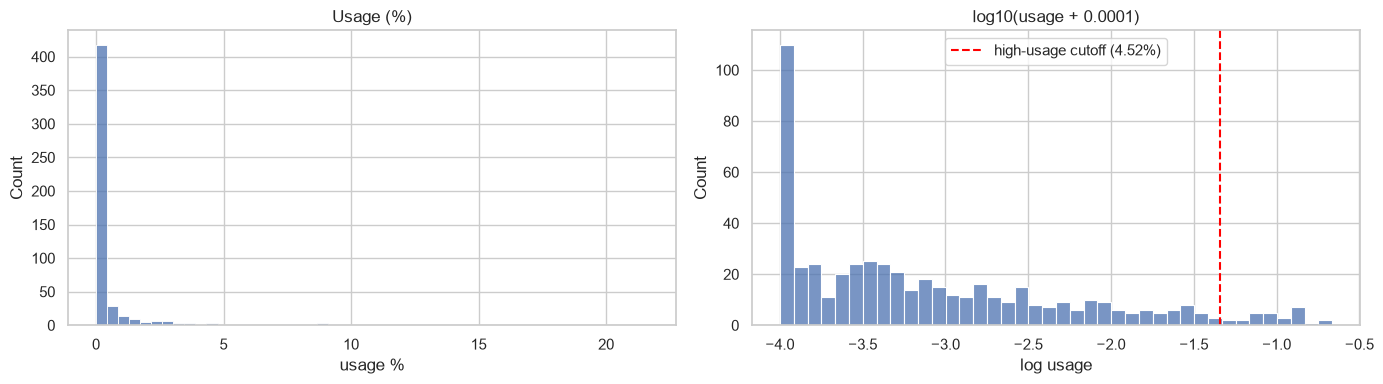

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(t["usage_mean"] * 100, bins=50, ax=axes[0])
axes[0].set(title="Usage (%)", xlabel="usage %")
sns.histplot(t["log_usage"], bins=40, ax=axes[1])
axes[1].axvline(np.log10(HIGH_USAGE + 1e-4), ls="--", color="red", label=f"high-usage cutoff ({HIGH_USAGE:.2%})")
axes[1].set(title="log10(usage + 0.0001)", xlabel="log usage"); axes[1].legend()
plt.tight_layout()

## 2. Strength vs usage

The clearest link in the analysis. Note the wide spread at every BST level: strength raises the odds, it does not decide them.

[Text(0.5, 0, 'BST'),
 Text(0, 0.5, 'log10(usage + 0.0001)'),
 Text(0.5, 1.0, 'BST vs usage: Spearman 0.512 (95% CI 0.443 to 0.579)')]

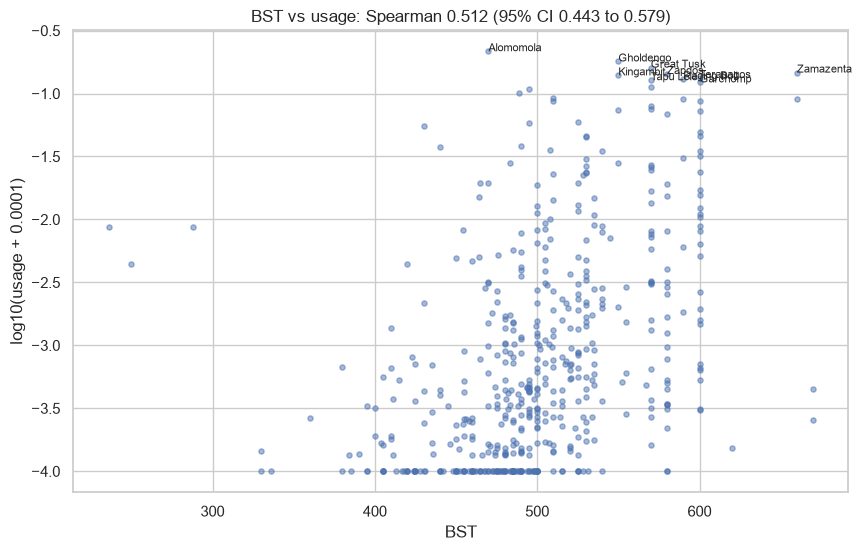

In [3]:
rho = summary["spearman_vs_usage"]["bst"]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(t["bst"], t["log_usage"], s=14, alpha=0.5)
for _, r in t.nlargest(10, "usage_mean").iterrows():
    ax.annotate(r["name"], (r["bst"], r["log_usage"]), fontsize=8)
ax.set(xlabel="BST", ylabel="log10(usage + 0.0001)",
       title=f"BST vs usage: Spearman {rho['rho']} (95% CI {rho['ci95'][0]} to {rho['ci95'][1]})")

## 3. Stat *shape* vs usage

Left and middle: the two role axes. Right: every rank correlation with its 95% bootstrap interval. Intervals crossing 0 (grey) mean no clear link.

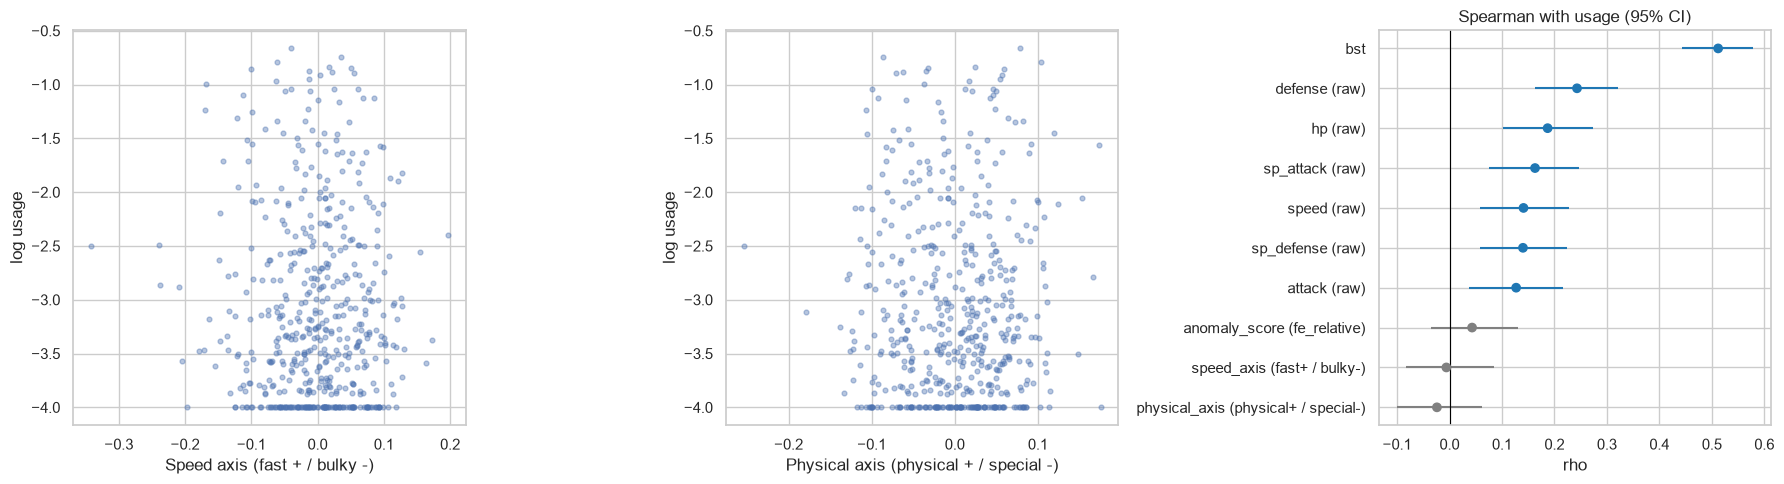

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in [(axes[0], "speed_axis", "Speed axis (fast + / bulky -)"),
                       (axes[1], "physical_axis", "Physical axis (physical + / special -)")]:
    ax.scatter(t[col], t["log_usage"], s=12, alpha=0.4)
    ax.set(xlabel=title, ylabel="log usage")

sp = pd.DataFrame(summary["spearman_vs_usage"]).T
sp[["lo", "hi"]] = pd.DataFrame(sp["ci95"].tolist(), index=sp.index)
sp = sp.sort_values("rho")
colors = ["tab:blue" if c else "grey" for c in sp["clear_link"]]
axes[2].hlines(sp.index, sp["lo"], sp["hi"], colors=colors)
axes[2].scatter(sp["rho"], sp.index, color=colors, zorder=3)
axes[2].axvline(0, color="black", lw=0.8)
axes[2].set(title="Spearman with usage (95% CI)", xlabel="rho")
plt.tight_layout()

## 4. Groups: descriptive clusters and types

Bars compare each group's share of the **high-usage** Pokémon with its share of **all** Pokémon. Only 29 Pokémon are high-usage, so a difference of 2–3 Pokémon looks large here. Treat these as hints.

Kruskal-Wallis across clusters: p = 0.80


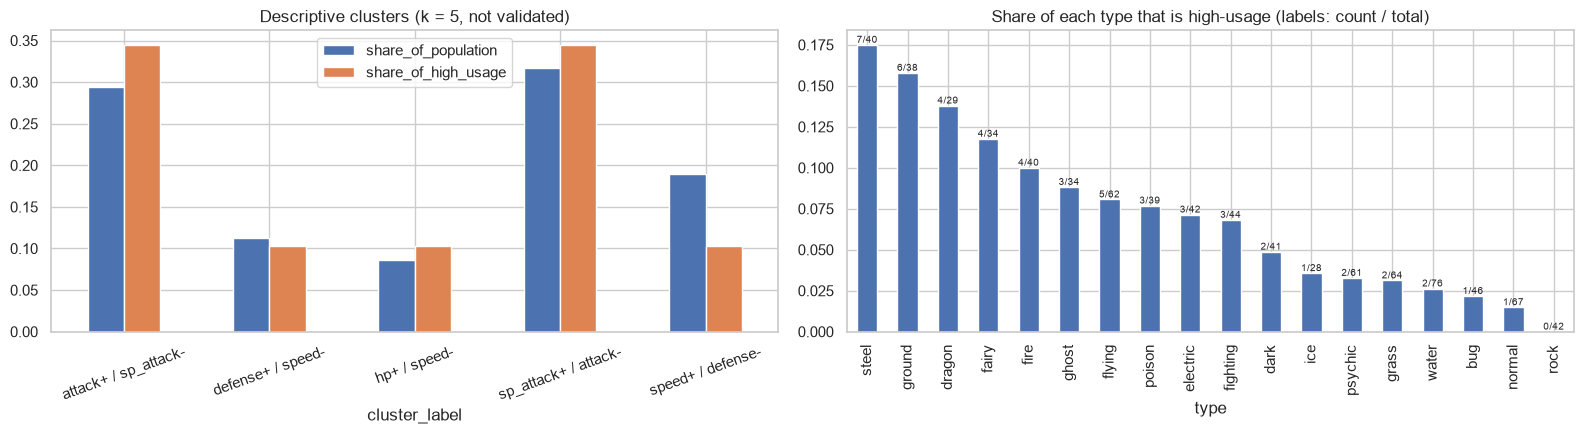

In [5]:
by_cluster = pd.read_csv(RESULTS_DIR / "competitive_by_cluster.csv", index_col=0)
by_type = pd.read_csv(RESULTS_DIR / "competitive_by_type.csv", index_col=0)
print(f"Kruskal-Wallis across clusters: p = {summary['kruskal_usage_by_cluster_p']:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
by_cluster[["share_of_population", "share_of_high_usage"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Descriptive clusters (k = 5, not validated)")

bt = by_type.sort_values("high_usage_share", ascending=False)
bt["high_usage_share"].plot.bar(ax=axes[1])
for i, (n, share) in enumerate(zip(bt["n"], bt["high_usage_share"])):
    axes[1].text(i, share, f"{round(share * n)}/{n}", ha="center", va="bottom", fontsize=7)
axes[1].set_title("Share of each type that is high-usage (labels: count / total)")
plt.tight_layout()

## 5. Stat twins with very different usage

Each pair is among the closest 25% of nearest-neighbour pairs in standardized stats. Similar numbers, very different popularity: the gap comes from what this project does not model (abilities, moves, typing, items).

In [6]:
pairs = pd.read_csv(RESULTS_DIR / "competitive_pairs.csv", index_col=0)
stats = t.set_index("name")[STAT_COLS + ["type_1", "type_2"]]
rows = []
for _, p in pairs.head(4).iterrows():
    for who, usage in ((p["a"], p["usage_a"]), (p["b"], p["usage_b"])):
        rows.append({"pair": f"{p['a']} / {p['b']}", "name": who, "usage %": round(usage * 100, 2),
                     **stats.loc[who].to_dict()})
pd.DataFrame(rows).set_index(["pair", "name"])

usage %   hp  attack  defense  sp_attack  \
pair                   name                                                   
Gholdengo / Glimmora   Gholdengo     17.97   87      60       95        133   
                       Glimmora       1.93   83      55       90        130   
Buzzwole / Great Tusk  Buzzwole       0.57  107     139      139         53   
                       Great Tusk    16.03  115     131      131         53   
Hydreigon / Moltres    Hydreigon      1.56   92     105       90        125   
                       Moltres        6.87   90     100       90        125   
Krookodile / Rillaboom Krookodile     0.19   95     117       80         65   
                       Rillaboom      4.58  100     125       90         60   

                                   sp_defense  speed  type_1    type_2  
pair                   name                                             
Gholdengo / Glimmora   Gholdengo           91     84   steel     ghost  
                       Glimmora            81     86    rock    poison  
Buzzwole / Great Tusk  Buzzwole            53     79     bug  fighting  
                       Great Tusk          53     87  ground  fighting  
Hydreigon / Moltres    Hydreigon           90     98    dark    dragon  
                       Moltres             85     90    fire    flying  
Krookodile / Rillaboom Krookodile          70     92  ground      dark  
                       Rillaboom           70     85   grass       NaN

## 6. Held-out prediction: does anything beyond BST help?

Same 50 cross-validation folds for every model. Right: per fold, richer model minus BST-only. Bars right of 0 = the richer model won that fold.

,mean_heldout_spearman,std,mean_gain_over_bst,share_of_folds_beating_bst
bst_ridge,0.510,0.076,NaN,NaN
full_ridge,0.549,0.075,0.039,0.64
full_forest,0.484,0.071,-0.026,0.32


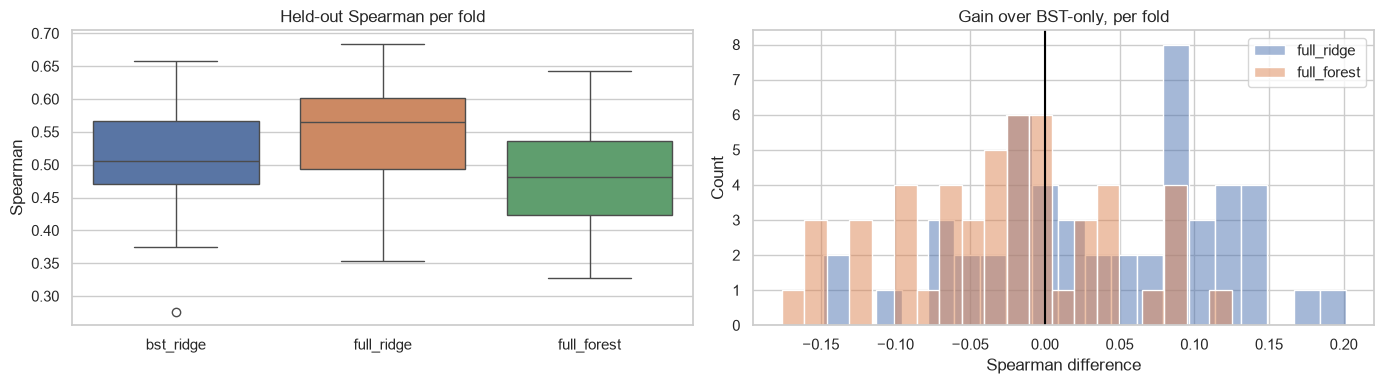

In [7]:
folds = pd.read_csv(RESULTS_DIR / "competitive_prediction_folds.csv")
models = ["bst_ridge", "full_ridge", "full_forest"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=folds[models], ax=axes[0])
axes[0].set(title="Held-out Spearman per fold", ylabel="Spearman")
for m in ["full_ridge", "full_forest"]:
    sns.histplot(folds[m] - folds["bst_ridge"], bins=20, alpha=0.5, label=m, ax=axes[1])
axes[1].axvline(0, color="black")
axes[1].set(title="Gain over BST-only, per fold", xlabel="Spearman difference"); axes[1].legend()
plt.tight_layout()
pd.DataFrame(prediction["models"]).T

### 7. Notes

**1. Research Question 4: Do discovered archetypes correspond to competitive usage patterns?**

- No stable archetypes were identified in the discovery analysis (EXP-04).
- The descriptive clusters also showed no significant difference in competitive usage (Kruskal-Wallis p = 0.80).
- Neither the speed axis (ρ = -0.006) nor the physical axis (ρ = -0.024) showed a meaningful relationship with usage.
- Adding stats, stat shares, and type flags to BST-only Ridge produced a small, inconsistent gain in held-out prediction (+0.039 in mean Spearman correlation). The full model performed better in only 64% of folds.
- Overall, discovered stat patterns do not meaningfully explain competitive usage. Additional features provide only modest predictive value beyond BST.

**2. Stat-twin pair: Gholdengo and Glimmora**

- Gholdengo and Glimmora have similar overall stat distributions, with a standardized stat distance of 0.541. Their individual stats are within approximately 10 points of each other.
- However, their typings differ significantly: Gholdengo is Steel/Ghost, while Glimmora is Rock/Poison.
- Gholdengo appears on 17.97% of teams compared with only 1.93% for Glimmora.
- This is a 16.04 percentage-point usage gap despite their similar base stats.
- This demonstrates that competitive popularity depends on more than stats. Typing, abilities, moves, items, and team synergy can make a substantial difference.

**3. Why did the Random Forest perform worse than BST alone?**

- Full Random Forest achieved a mean held-out Spearman of 0.484, below BST-only Ridge at 0.510.
- It only beat BST-only in 16 of 50 folds (32%), with an average performance difference of -0.026.
- The model used 30 features across only 523 Pokémon, with just 29 high-usage examples.
- This limited dataset makes it easier for the forest to learn patterns in its training data that do not generalize to unseen Pokémon.
- Ridge regression likely performs better because its simpler, regularized structure is more appropriate for this dataset.

**4. One limitation of the usage data**

- Usage measures how frequently a Pokémon appears on teams, not its win rate or actual competitive strength.
- The data is limited to Gen 9 National Dex at skill level 1630, averaged across July–September 2026. Results may differ across formats, skill levels, and time periods.
- Approximately 27% of total usage comes from forms outside the dataset, including Mega Evolutions, alternate forms, and regional forms.
- Only 29 of 523 legal Pokémon meet the high-usage cutoff, so group-level comparisons should be interpreted cautiously.

**Overall Takeaway:**

No stable stat-based archetypes were discovered, and the descriptive clusters did not show meaningful differences in competitive usage. BST provides a useful baseline for predicting usage, but adding individual stats, stat shares, and typing produces only a small and inconsistent improvement. Ultimately, competitive viability depends on factors beyond base stats, including typing, abilities, moves, and team synergy.